<a href="https://colab.research.google.com/github/nicolemaracaja/laboratorios_LLM/blob/main/%5B123111413%5Dlab_word_embeddings_gensim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratório: Word Embeddings com Gensim

**Disciplina:** Modelos de Linguagem de Grande Escala, UFCG
**Pré-requisito:** notebook *Tutorial: Word Embeddings com Gensim*
**Entrega:** este notebook executado (Arquivo > Baixar > .ipynb), com todas as células rodadas e as respostas escritas preenchidas.

| Nome | Matrícula |
|---|---|
| | |

### Objetivos
Ao final do laboratório você deverá ser capaz de:
1. Avaliar embeddings de forma intrínseca (analogias e similaridade de pares) e interpretar os números.
2. Construir e testar analogias e conjuntos de `doesnt_match`, explicando os acertos e os erros.
3. Investigar polissemia em embeddings estáticos.
4. Projetar o espaço vetorial em 2D e discutir o que PCA e t-SNE preservam e distorcem.
5. Medir um viés de gênero no espaço vetorial e refletir sobre suas consequências.

### Regras
- Células marcadas com `# TODO` devem ser completadas por você. Células com **✍️ Resposta** pedem texto curto (3 a 6 linhas).
- **Uso de IA é permitido** para gerar ou ajustar código, desde que você preencha a declaração na Parte 6 e seja capaz de explicar o que cada trecho faz.
- As respostas escritas devem se apoiar nos **resultados que você obteve**, citando números e exemplos do seu notebook.

### Distribuição de pontos

| Parte | Tema | Pontos |
|---|---|---|
| 1 | Avaliação intrínseca | 2,0 |
| 2 | Analogias próprias | 2,0 |
| 3 | `doesnt_match` e polissemia | 1,5 |
| 4 | Visualização em espaços reduzidos | 2,0 |
| 5 | Viés de gênero | 1,5 |
| 6 | Reflexão final e declaração de uso de IA | 1,0 |
| Bônus | Treinar e comparar Word2Vec no text8 | +1,0 |

## Parte 0: Configuração (não vale pontos)

In [ ]:
!pip install -q gensim
# Se aparecer erro de compatibilidade com numpy/scipy, reinicie a sessão
# (Ambiente de execução > Reiniciar sessão) e rode novamente a partir daqui.

In [ ]:
import gensim
import gensim.downloader as api
from gensim.models import Word2Vec
from gensim.test.utils import datapath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("gensim", gensim.__version__)

gensim 4.4.0


In [ ]:
# Carrega dois modelos GloVe (Wikipedia + Gigaword) com dimensões diferentes.
# O download leva 1–3 minutos na primeira vez.
wv50  = api.load("glove-wiki-gigaword-50")
wv100 = api.load("glove-wiki-gigaword-100")
wv = wv100   # modelo principal do laboratório

print(f"Vocabulário: {len(wv):,} palavras | dimensões: {wv50.vector_size} e {wv100.vector_size}")

Vocabulário: 400,000 palavras | dimensões: 50 e 100


## Parte 1: Avaliação intrínseca (2,0 pontos)

Como saber se um embedding é "bom"? Uma forma é a **avaliação intrínseca**, que testa o espaço vetorial diretamente em tarefas linguísticas, sem treinar um classificador em cima dele. O gensim já traz três conjuntos clássicos:

- **Google Analogy** (`questions-words.txt`, Mikolov et al., 2013): cerca de 19 mil analogias em 14 categorias. As 5 primeiras são **semânticas** (capitais, moedas, família...) e as 9 últimas, **sintáticas** (plural, comparativo, tempo verbal...).
- **WordSim-353**: pares de palavras com notas humanas de **relação** (*relatedness*), por exemplo *coffee–cup* recebe nota alta.
- **SimLex-999**: pares com notas humanas de **similaridade estrita**, por exemplo *coffee–cup* recebe nota baixa, porque café não é parecido com xícara.

Para os pares, a métrica é a **correlação de Spearman** entre as notas humanas e as similaridades de cosseno do modelo.

### 1.1 Analogias por categoria
A célula abaixo já está pronta. Ela avalia o modelo de 100 dimensões e mostra a acurácia por categoria.

In [ ]:
def avaliar_analogias_google(modelo, restrict_vocab=100_000):
    acc_total, secoes = modelo.evaluate_word_analogies(
        datapath("questions-words.txt"), restrict_vocab=restrict_vocab
    )
    linhas = []
    for s in secoes:
        n = len(s["correct"]) + len(s["incorrect"])
        if n and s["section"] != "Total accuracy":
            linhas.append({"categoria": s["section"], "n": n,
                           "acurácia": len(s["correct"]) / n})
    return acc_total, pd.DataFrame(linhas)

acc100, df100 = avaliar_analogias_google(wv100)
print(f"Acurácia total (100d): {acc100:.3f}")
df100.style.format({"acurácia": "{:.3f}"})

Acurácia total (100d): 0.639


,categoria,n,acurácia
0,capital-common-countries,506,0.939
1,capital-world,4446,0.898
2,currency,752,0.156
3,city-in-state,2467,0.308
4,family,506,0.816
5,gram1-adjective-to-adverb,992,0.244
6,gram2-opposite,756,0.217
7,gram3-comparative,1332,0.791
8,gram4-superlative,1056,0.561
9,gram5-present-participle,1056,0.696


### 1.2 TODO: compare 50d e 100d
Complete a célula para:
1. Avaliar também o `wv50` nas analogias.
2. Avaliar **os dois modelos** em WordSim-353 e SimLex-999 com `modelo.evaluate_word_pairs(datapath("wordsim353.tsv"))` e `datapath("simlex999.txt")`. O método retorna `(pearson, spearman, oov_ratio)`; use o coeficiente de **Spearman** (`spearman[0]`).
3. Montar um `DataFrame` com uma linha por modelo e as colunas `analogias`, `wordsim353` e `simlex999`.

In [ ]:
# TODO: avalie wv50 nas analogias
acc50, df50 = avaliar_analogias_google(wv50)

# TODO: avalie os dois modelos em WordSim-353 e SimLex-999 (Spearman)
resultados = []
for nome, modelo, acc in [("GloVe 50d", wv50, acc50), ("GloVe 100d", wv100, acc100)]:
    ws  = modelo.evaluate_word_pairs(datapath("wordsim353.tsv"))[1][0]   # Spearman no wordsim353
    sl  = modelo.evaluate_word_pairs(datapath("simlex999.txt"))[1][0]   # Spearman no simlex999

    resultados.append({"modelo": nome, "analogias": acc, "wordsim353": ws, "simlex999": sl})

tabela = pd.DataFrame(resultados).set_index("modelo")
tabela.round(3)

,analogias,wordsim353,simlex999
modelo,,,
GloVe 50d,0.470,0.503,0.263
GloVe 100d,0.639,0.533,0.296


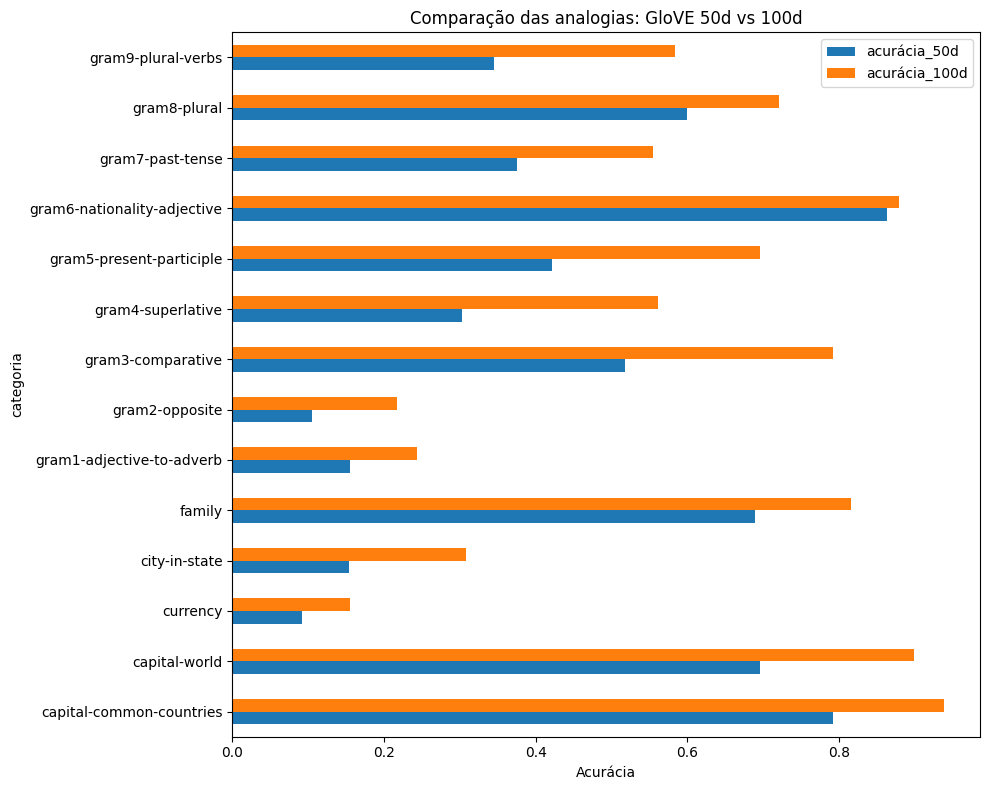

In [ ]:
# TODO: gráfico de barras comparando a acurácia por categoria (50d vs 100d)
# Dica: junte df50 e df100 pela coluna "categoria" e use .plot.barh()

comparacao = df50.merge(df100, on="categoria", suffixes=["_50d", "_100d"])

comparacao.set_index("categoria")[["acurácia_50d", "acurácia_100d"]].plot.barh(
    figsize=(10,8),
    xlabel="Acurácia",
    title="Comparação das analogias: GloVE 50d vs 100d"
)

plt.tight_layout()
plt.show()

**Pergunta 1.1** Quais categorias de analogia o modelo resolve melhor e quais resolve pior? Levante uma hipótese que explique a diferença (pense em frequência das palavras e em quanto o contexto local revela cada relação).

**✍️ Resposta 1.1:**

O modelo resolve melhor as categorias `capital-common-countries` e `capital-world`. E resolve pior as categorias `currency` e `gram2-opposite`. Uma hipótese possível para explicar essa diferença é que relações como países e capitais aparecem frequentemente nos dados e em contextos que ajudem a relacionar essas palavras. Já moedas e opostos podem aparecer em contextos variados, dificultanto a identificação de uma possível relação.

**Pergunta 1.2** O que aconteceu ao passar de 50 para 100 dimensões? Por que a correlação no SimLex-999 é bem menor que no WordSim-353 para os dois modelos?

**✍️ Resposta 1.2:**

Ao passar de 50 para 100 dimensões, o modelo melhora nas 3 avaliações, o que indica que o modelo de 100 dimensões representou melhor as relações entre palavras. A correlação no SimLex-999 é bem menor que no WordSim-353 em ambos os modelos porque o SimLex avalia se duas palavras compartilham os mesmos traços semânticos, o que é mais restritivo, já o WordSim avalia se duas palavras pertencem ao mesmo assunto ou contexto. Logo, palavras relacionadas, mas não necessariamente semelhantes, recebem notas altas no WordSim-353.


## Parte 2: Suas próprias analogias (2,0 pontos)

### 2.1 TODO: implemente o avaliador
Complete `avaliar_analogias`, que recebe uma lista de tuplas `(a, b, c, d)` representando *a : b :: c : d* e calcula:
- **acc@1**: fração em que `d` é a **primeira** resposta;
- **acc@5**: fração em que `d` está entre as **5 primeiras**.

O parâmetro `metodo` escolhe entre `"add"` (3CosAdd, `most_similar`) e `"mul"` (3CosMul, `most_similar_cosmul`). Analogias com palavras fora do vocabulário devem ser ignoradas e contadas à parte.

In [ ]:
def avaliar_analogias(wv, analogias, metodo="add", topn=5):
    acertos1, acertos5, avaliadas, oov = 0, 0, 0, 0
    detalhes = []   # lista de dicts com a, b, c, esperado, previsto_top5
    for a, b, c, d in analogias:

        if any(palavra not in wv for palavra in (a, b, c, d)):
          oov += 1
          continue
        if metodo == "add":
          resultados = wv.most_similar(positive=[b, c],
                                       negative=[a],
                                       topn=topn)
        elif metodo == "mul":
          resultados = wv.most_similar_cosmul(positive=[b, c],
                                              negative=[a],
                                              topn=topn)
        previstos = [palavra for palavra, similaridade in resultados]
        avaliadas += 1

        if previstos and previstos[0] == d:
          acertos1 += 1
        if d in previstos[:5]:
          acertos5 += 1

        detalhes.append({"a": a, "b": b, "c": c, "esperado": d, "previstos_top5": previstos, "acertou@1": previstos[0] == d if previstos else False})

    return {"acc@1": acertos1 / max(avaliadas, 1),
            "acc@5": acertos5 / max(avaliadas, 1),
            "avaliadas": avaliadas, "oov": oov}, pd.DataFrame(detalhes)

### 2.2 TODO: crie seu conjunto de analogias
Crie **pelo menos 12 analogias**, com no mínimo 4 em cada uma de **3 categorias diferentes** de sua escolha. Evite as categorias que já existem no Google Analogy (capitais, moedas, plural...). Sugestões: animal → filhote, instrumento → músico, país → idioma, empresa → produto, ferramenta → ação, esporte → equipamento, cor → objeto típico.

Lembre-se: o vocabulário do GloVe está **em inglês e em minúsculas**.

In [ ]:
minhas_analogias = {
    "categoria_1": [
        ("dog", "puppy", "cat", "kitten"),
        ("cow", "calf", "horse", "foal"),
        ("sheep", "lamb", "goat", "kid"),
        ("duck", "duckling", "chicken", "chick"),
    ],
    "categoria_2": [
        ("guitar", "guitarist", "piano", "pianist"),
        ("violin", "violinist", "drums", "drummer"),
        ("flute", "flutist", "trumpet", "trumpeter"),
        ("saxophone", "saxophonist", "cello", "cellist"),
    ],
    "categoria_3": [
        ("tennis", "racket", "hockey", "stick"),
        ("boxing", "gloves", "skiing", "skis"),
        ("archery", "bow", "fencing", "sword"),
        ("golf", "club", "baseball", "bat"),
    ],
}

In [ ]:
# Avalia cada categoria com os dois métodos (pronto, apenas execute)
linhas, todos_detalhes = [], []
for cat, lista in minhas_analogias.items():
    for metodo in ["add", "mul"]:
        res, det = avaliar_analogias(wv, lista, metodo=metodo)
        linhas.append({"categoria": cat, "método": "3CosAdd" if metodo == "add" else "3CosMul", **res})
        if metodo == "add":
            todos_detalhes.append(det.assign(categoria=cat))

display(pd.DataFrame(linhas).round(2))
detalhes = pd.concat(todos_detalhes, ignore_index=True)
detalhes[~detalhes["acertou@1"]]   # apenas os erros (3CosAdd)

,categoria,método,acc@1,acc@5,avaliadas,oov
0,categoria_1,3CosAdd,0.00,0.25,4,0
1,categoria_1,3CosMul,0.25,0.25,4,0
2,categoria_2,3CosAdd,0.50,0.75,4,0
3,categoria_2,3CosMul,0.25,0.75,4,0
4,categoria_3,3CosAdd,0.25,0.25,4,0
5,categoria_3,3CosMul,0.25,0.25,4,0


,a,b,c,esperado,previstos_top5,acertou@1,categoria
0,dog,puppy,cat,kitten,"[puppies, kitten, kittens, monkey, rabbit]",False,categoria_1
1,cow,calf,horse,foal,"[ankle, leg, knee, trainer, roping]",False,categoria_1
2,sheep,lamb,goat,kid,"[roast, roasted, sauce, chicken, fried]",False,categoria_1
3,duck,duckling,chicken,chick,"[applesauce, ricotta, boned, chunky, yolks]",False,categoria_1
6,flute,flutist,trumpet,trumpeter,"[clarinetist, flautist, trombonist, harpist, o...",False,categoria_2
7,saxophone,saxophonist,cello,cellist,"[pianist, violinist, cellist, composer, flautist]",False,categoria_2
8,tennis,racket,hockey,stick,"[puck, pucks, skates, rackets, backfield]",False,categoria_3
10,archery,bow,fencing,sword,"[walls, bridge, locks, pin, roof]",False,categoria_3
11,golf,club,baseball,bat,"[league, football, leagues, sox, yankees]",False,categoria_3


**Pergunta 2.1** Compare as categorias e os dois métodos. Em seguida, escolha **dois erros** da tabela acima e explique cada um: a resposta do modelo é absurda ou "quase certa"? Ela revela algo sobre os dados de treino ou sobre a própria relação?

**✍️ Resposta 2.1:**

A categoria de instrumentos e músicos apresentou os melhores resultados. O 3CosAdd teve melhor desempenho na primeira posição, mas considerando as 5 primeiras, os dois empataram.

Erro 1: Na analogia `dog : puppy :: cat : kitten`, o modelo sugeriu puppies antes de kitten, a resposta é quase certa porque é relacionada, mas incorreta.

Erro 2: Na analogia `cow : calf :: horse : foal`, o modelo sugeriu palavras como leg e knee, que significam “perna” e “joelho”. Essas respostas são um pouco absurdas, pois não tem relação direta com a relação entre um animal e seu filhote.

## Parte 3: `doesnt_match` e polissemia (1,5 pontos)

### 3.1 TODO: grupos com intruso
Crie **6 grupos** de 4 a 6 palavras, cada um com um intruso:
- 3 grupos **fáceis** (o intruso é de outro domínio, ex.: frutas + um teclado);
- 3 grupos **difíceis** (o intruso é do mesmo domínio, mas difere em algum traço, ex.: animais domésticos + um selvagem, ou cores + uma que também é fruta).

In [ ]:
grupos = [
    # Grupos fáceis
    (["apple", "banana", "orange", "grape", "pineapple", "car"], "car", "facil"),
    (["dog", "cat", "horse", "rabbit", "monkey", "pizza"], "pizza", "facil"),
    (["monday", "tuesday", "wednesday", "friday", "sunday", "pencil"], "pencil", "facil"),

    # Grupos difíceis
    (["apple", "banana", "orange", "grape", "pineapple", "potato"], "potato", "difícil"),
    (["dog", "cat", "hamster", "rabbit", "bird", "lion"], "lion", "difícil"),
    (["monday", "tuesday", "wednesday", "friday", "sunday", "january"], "january", "difícil"),
]

for palavras, esperado, nivel in grupos:
    previsto = wv.doesnt_match(palavras)
    marca = "✅" if previsto == esperado else "❌"
    print(f"{marca} [{nivel:7s}] {palavras} → previsto: {previsto} | esperado: {esperado}")

✅ [facil  ] ['apple', 'banana', 'orange', 'grape', 'pineapple', 'car'] → previsto: car | esperado: car
✅ [facil  ] ['dog', 'cat', 'horse', 'rabbit', 'monkey', 'pizza'] → previsto: pizza | esperado: pizza
✅ [facil  ] ['monday', 'tuesday', 'wednesday', 'friday', 'sunday', 'pencil'] → previsto: pencil | esperado: pencil
❌ [difícil] ['apple', 'banana', 'orange', 'grape', 'pineapple', 'potato'] → previsto: orange | esperado: potato
❌ [difícil] ['dog', 'cat', 'hamster', 'rabbit', 'bird', 'lion'] → previsto: hamster | esperado: lion
✅ [difícil] ['monday', 'tuesday', 'wednesday', 'friday', 'sunday', 'january'] → previsto: january | esperado: january


### 3.2 TODO: separando sentidos com aritmética vetorial
Embeddings estáticos atribuem **um único vetor** a cada palavra, que mistura todos os seus sentidos. Para cada palavra ambígua da lista:
1. mostre os 8 vizinhos mais próximos;
2. **subtraia** uma palavra associada a um dos sentidos e veja os vizinhos que sobram. Exemplo: `wv.most_similar(positive=["bank"], negative=["money"])`.

Complete o dicionário com mais **três** palavras ambíguas à sua escolha.

In [ ]:
ambiguas = {
    # palavra: (palavra de um sentido, palavra do outro sentido)
    "bank":  ("money", "river"),
    "apple": ("iphone", "fruit"),
    "bat":   ("baseball", "animal"),
    "mouse": ("computer", "animal"),
    "crane": ("construction", "bird"),
}

for palavra, (s1, s2) in ambiguas.items():
    print(f"\n=== {palavra} ===")
    print("vizinhos:       ", [w for w, _ in wv.most_similar(palavra, topn=8)])
    print(f"menos '{s1}':", [w for w, _ in wv.most_similar(positive=[palavra], negative=[s1], topn=8)])
    print(f"menos '{s2}':", [w for w, _ in wv.most_similar(positive=[palavra], negative=[s2], topn=8)])


=== bank ===
vizinhos:        ['banks', 'banking', 'credit', 'investment', 'financial', 'securities', 'lending', 'funds']
menos 'money': ['toronto-dominion', 'nedcor', 'aozora', 'umum', 'shinsei', 'fukutoku', 'handlowy', 'danske']
menos 'river': ['hsbc', 'ubs', 'commerzbank', 'dresdner', 'citibank', 'nomura', 'banking', 'ufj']

=== apple ===
vizinhos:        ['microsoft', 'ibm', 'intel', 'software', 'dell', 'pc', 'macintosh', 'iphone']
menos 'iphone': ['berry', 'curry', 'grove', 'pecan', 'cherry', 'peach', 'groves', 'pine']
menos 'fruit': ['microsoft', 'aol', 'google', 'realnetworks', 'intel', 'sony', 'yahoo', 'ibm']

=== bat ===
vizinhos:        ['bats', 'balls', 'pitch', 'batting', 'wicket', 'ball', 'toss', 'innings']
menos 'baseball': ['katich', 'misbah', 'solanki', 'bowled', 'hussey', 'wicket', 'gully', 'parore']
menos 'animal': ['daubenton', 'batsman', 'ganguly', 'batted', 'tendulkar', 'toss', 'dravid', 'collingwood']

=== mouse ===
vizinhos:        ['cat', 'rabbit', 'monkey', 'm

**Pergunta 3.1** Os grupos difíceis enganaram o modelo? Analise um acerto e um erro com base no mecanismo do `doesnt_match`, que calcula a média dos vetores e retorna a palavra mais distante dela.

**✍️ Resposta 3.1:**

Sim. Un acerto foi o grupo de dias de semana com `january`, em que o modelo identificou o mês como intruso, pois o seu vetor ficou mais distante da média dos vetores dos dias de semana. Um erro foi no grupo das frutas com `potato` como intruso, e esse erro ocorre porque o modelo considera a distância dos vetores em relação à media do grupo e não categorias semânticas rígidas. E como `potato` está semanticamente próxima das frutas, ocorre esse erro.

**Pergunta 3.2** A subtração vetorial conseguiu "isolar" sentidos? Qual sentido é dominante em cada palavra e por quê? Que tipo de modelo resolveria esse problema de forma mais fundamentada?

**✍️ Resposta 3.2:**

Não perfeitamente. Em alguns casos, um sentido pareceu mais forte que o outro, como em `bank`, que pode estar mais associado ao contexto financeiro. Já no caso de `crane`, mesmo subtraindo palavras relacionadas a um dos sentidos, ainda apareceram termos ligados à construção. Isso acontece porque o GloVe representa cada palavra com um único vetor, misturando seus diferentes significados. Um modelo como o BERT resolveria melhor esse problema, pois considera o contexto da frase e consegue representar a mesma palavra de formas diferentes, a depender do significado.

## Parte 4: Visualização em espaços reduzidos (2,0 pontos)

### 4.1 TODO: escolha suas categorias
Defina **5 categorias** com **8 palavras** cada. Ao menos **uma** delas deve ser "difícil" de separar de outra (ex.: *frutas* e *cores*, *esportes* e *países*, *emoções positivas* e *emoções negativas*).

In [ ]:
categorias = {
    "frutas": [
        "apple", "banana", "grape", "lemon",
        "orange", "mango", "peach", "cherry"
    ],
    "cores": [
        "red", "blue", "green", "yellow",
        "orange", "purple", "pink", "brown"
    ],
    "animais": [
        "dog", "cat", "horse", "rabbit",
        "tiger", "lion", "monkey", "elephant"
    ],
    "profissoes": [
        "doctor", "teacher", "engineer", "lawyer",
        "nurse", "scientist", "artist", "chef"
    ],
    "esportes": [
        "football", "basketball", "tennis", "soccer",
        "volleyball", "baseball", "golf", "hockey"
    ]
}

palavras, rotulos = [], []
for cat, lista in categorias.items():
    for p in lista:
        if p in wv:
            palavras.append(p); rotulos.append(cat)
        else:
            print("fora do vocabulário:", p)
X = np.array([wv[p] for p in palavras])
cores = dict(zip(categorias, plt.cm.tab10.colors))
print(X.shape)

(40, 100)


In [ ]:
def plotar_2d(coords, titulo, ax=None):
    ax = ax or plt.figure(figsize=(9, 7)).gca()
    for cat in categorias:
        idx = [i for i, r in enumerate(rotulos) if r == cat]
        ax.scatter(coords[idx, 0], coords[idx, 1], color=cores[cat], label=cat, s=40)
        for i in idx:
            ax.annotate(palavras[i], coords[i], xytext=(3, 2), textcoords="offset points", fontsize=8)
    ax.set_title(titulo); ax.grid(alpha=.3)
    return ax

### 4.2 TODO: PCA e t-SNE lado a lado
Gere uma figura com **4 subplots**: PCA e t-SNE com `perplexity` igual a 5, 15 e 30. Use `random_state=42`. Mostre no título do PCA a **variância explicada** pelos 2 componentes.

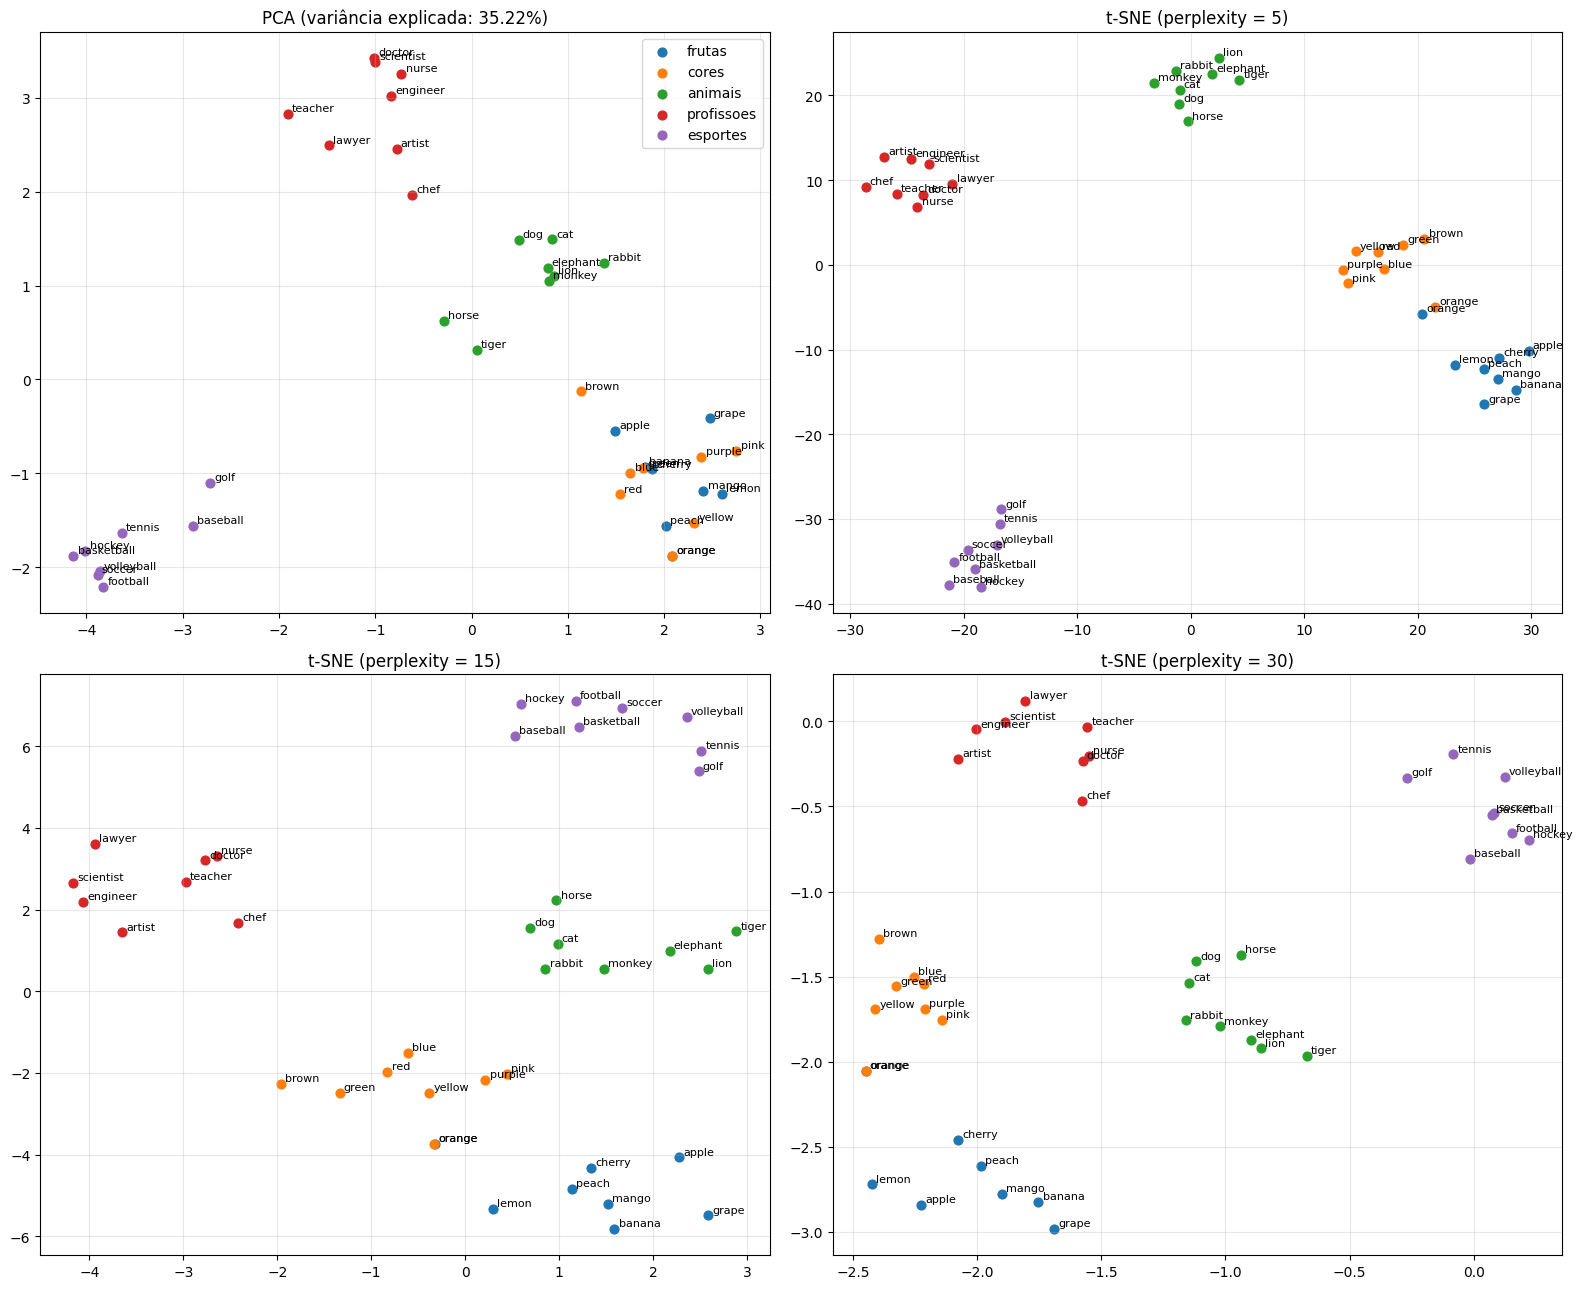

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# TODO: PCA em axes[0, 0]
pca = PCA(n_components=2, random_state=42)
coords_pca = pca.fit_transform(X)

variancia = pca.explained_variance_ratio_.sum() * 100

plotar_2d(
    coords_pca,
    f"PCA (variância explicada: {variancia:.2f}%)",
    ax=axes[0, 0]
)

# TODO: t-SNE com perplexity 5, 15 e 30 nos demais eixos

# t-SNE com perplexity = 5
tsne5 = TSNE(n_components=2, perplexity=5, random_state=42)
coords_tsne5 = tsne5.fit_transform(X)

plotar_2d(
    coords_tsne5,
    "t-SNE (perplexity = 5)",
    ax=axes[0, 1]
)

# t-SNE com perplexity = 15
tsne15 = TSNE(n_components=2, perplexity=15, random_state=42)
coords_tsne15 = tsne15.fit_transform(X)

plotar_2d(
    coords_tsne15,
    "t-SNE (perplexity = 15)",
    ax=axes[1, 0]
)

# t-SNE com perplexity = 30
tsne30 = TSNE(n_components=2, perplexity=30, random_state=42)
coords_tsne30 = tsne30.fit_transform(X)

plotar_2d(
    coords_tsne30,
    "t-SNE (perplexity = 30)",
    ax=axes[1, 1]
)


axes[0, 0].legend()
plt.tight_layout(); plt.show()

### 4.3 TODO: uma relação como direção
Escolha uma **relação** (diferente de gênero e de país → capital, que já aparecem no tutorial) e pelo menos **6 pares** que a exemplifiquem. Use a função `plotar_relacoes` do tutorial, copiada abaixo, para desenhar as setas no plano do PCA.

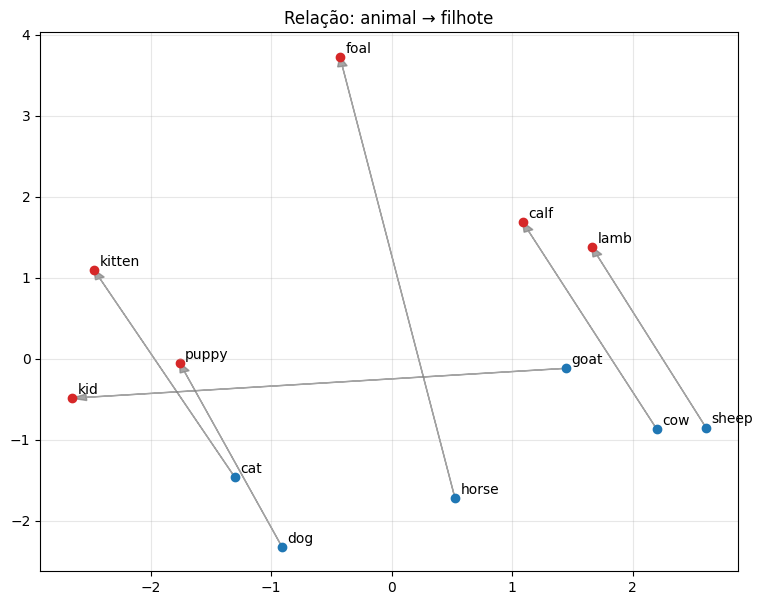

In [ ]:
def plotar_relacoes(pares, titulo):
    ps = [p for par in pares for p in par]
    coords = PCA(n_components=2, random_state=42).fit_transform(np.array([wv[p] for p in ps]))
    plt.figure(figsize=(9, 7))
    for i in range(0, len(ps), 2):
        (x0, y0), (x1, y1) = coords[i], coords[i + 1]
        plt.arrow(x0, y0, x1 - x0, y1 - y0, head_width=0.08, length_includes_head=True, color="gray", alpha=.7)
        plt.scatter([x0], [y0], color="tab:blue"); plt.scatter([x1], [y1], color="tab:red")
        plt.annotate(ps[i], (x0, y0), xytext=(4, 3), textcoords="offset points")
        plt.annotate(ps[i + 1], (x1, y1), xytext=(4, 3), textcoords="offset points")
    plt.title(titulo); plt.grid(alpha=.3); plt.show()

# TODO: defina seus pares e chame plotar_relacoes
meus_pares = [
    ("dog", "puppy"),
    ("cat", "kitten"),
    ("cow", "calf"),
    ("horse", "foal"),
    ("sheep", "lamb"),
    ("goat", "kid"),
]

plotar_relacoes(meus_pares, "Relação: animal → filhote")

**Pergunta 4.1** Compare PCA e t-SNE: qual separa melhor as suas categorias? O que muda quando a `perplexity` aumenta? Em qual método é legítimo comparar a **distância entre grupos diferentes**? Comente o par de categorias "difícil" que você escolheu.

**✍️ Resposta 4.1:**

O t-SNE separou melhor as categorias visualmente, enquanto no PCA algumas palavras de frutas e cores ficaram mais próximas. Ao aumentar a perplexity de 5 para 15 para 30, a organização dos grupos mudou, sendo a perplexidade 5 a que os itens mais ficaram agrupados, ou seja, conforme a perplexity aumenta, os grupos ficam mais afastados. A distância entre os grupos pode ser interpretada com mais confiança no PCA do que no t-SNE, pois este prioriza as relações entre pontos próximos. No caso de frutas e cores, a palavra orange pertence às duas categorias, o que ajuda a explicar por que elas podem ficar próximas no gráfico.

**Pergunta 4.2** As setas da sua relação ficaram aproximadamente paralelas? Por que esse teste deve ser feito com PCA e não com t-SNE? O que o paralelismo diz sobre o funcionamento das analogias da Parte 2?

**✍️ Resposta 4.2:**

As setas não ficaram totalmente paralelas, mas algumas apresentam direções parecidas. Isso mostra que o modelo consegue representar essa relação de forma semelhante em alguns casos, mas não em todos. O PCA é mais adequado para essa análise porque preserva as relações lineares entre os vetores, enquanto o t-SNE prioriza a proximidade entre palavras e pode distorcer essas direções. Isso ajuda a entender como funcionam as analogias da Parte 2: quando palavras apresentam relações semelhantes no espaço vetorial, podemos usar operações com seus vetores para tentar encontrar outras palavras que sigam a mesma relação. Porém, como as direções não são exatamente iguais, o modelo pode não acertar todas as analogias.

## Parte 5: Medindo viés de gênero (1,5 pontos)

Bolukbasi et al. (2016) mostraram que é possível identificar uma **direção de gênero** no espaço vetorial e medir o quanto palavras supostamente neutras, como profissões, se inclinam para um dos lados.

### 5.1 TODO: construa o eixo de gênero
1. Calcule o eixo como a **média** das diferenças normalizadas `wv[m] - wv[f]` para os pares definidos abaixo e normalize o resultado (norma 1).
2. Para cada profissão, calcule a **similaridade de cosseno** com o eixo. Valores positivos significam inclinação ao masculino; negativos, ao feminino.
3. Faça um gráfico de barras horizontais ordenado pelo valor.

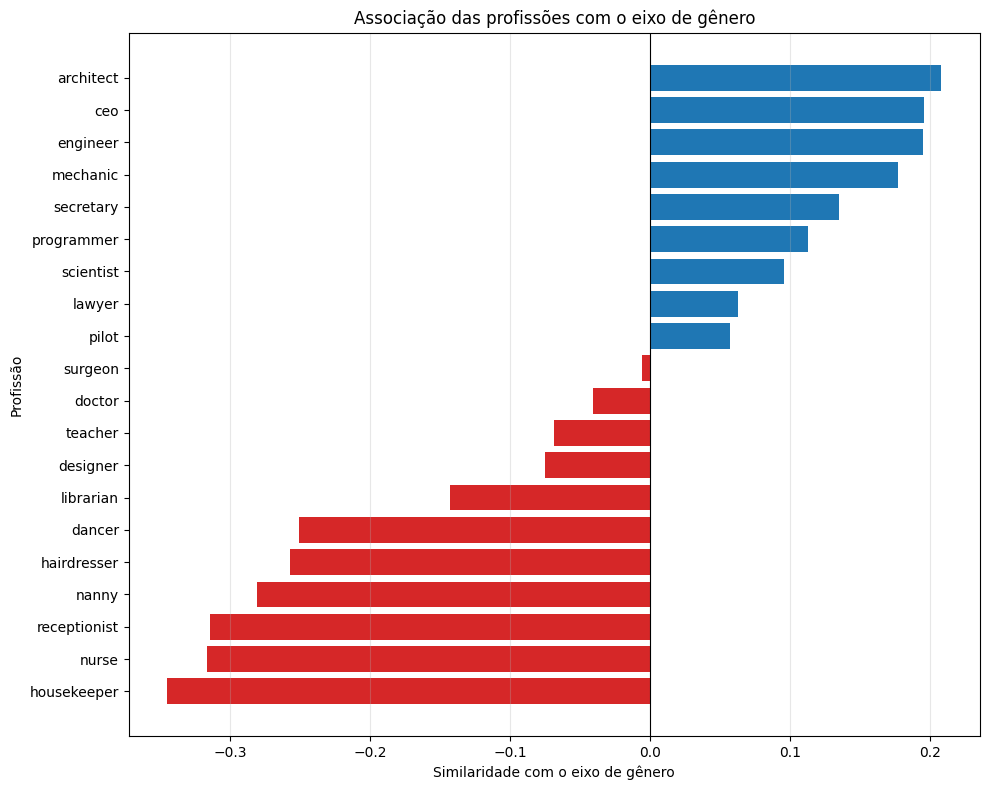

In [ ]:
pares_genero = [("he", "she"), ("man", "woman"), ("his", "her"),
                ("male", "female"), ("boy", "girl"), ("father", "mother")]

profissoes = ["doctor", "nurse", "engineer", "teacher", "programmer", "secretary",
              "scientist", "receptionist", "pilot", "librarian", "ceo", "housekeeper",
              "surgeon", "dancer", "mechanic", "hairdresser", "architect", "nanny",
              "lawyer", "designer"]

def normalizar(v):
    return v / np.linalg.norm(v)

# TODO: eixo de gênero
diferencas = [
    normalizar(wv[m])- normalizar(wv[f])
    for m, f in pares_genero
]

eixo = normalizar(np.mean(diferencas, axis=0))

# TODO: projeções (cosseno entre wv[p] normalizado e o eixo)
projecoes = pd.Series({p: np.dot(normalizar(wv[p]), eixo) for p in profissoes}).sort_values()

# TODO: gráfico de barras horizontais (cores diferentes para valores positivos e negativos)
cores_barras = [
    "tab:blue" if valor >= 0 else "tab:red"
    for valor in projecoes.values
]

plt.figure(figsize=(10, 8))
plt.barh(projecoes.index, projecoes.values, color=cores_barras)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Similaridade com o eixo de gênero")
plt.ylabel("Profissão")
plt.title("Associação das profissões com o eixo de gênero")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Sanidade: palavras com gênero definido devem ficar nos extremos e palavras neutras perto de zero.
# TODO: calcule a projeção de 4 palavras com gênero explícito (ex.: "king", "queen", "actor", "actress")
#       e de 4 palavras que você considera neutras (ex.: "table", "water", "computer", "tree").

# Palavras com gênero explícito
palavras_genero = ["king", "queen", "actor", "actress"]

# Palavras consideradas neutras
palavras_neutras = ["table", "water", "computer", "tree"]

controles = palavras_genero + palavras_neutras

projecoes_controle = pd.Series({
    p: np.dot(normalizar(wv[p]), eixo)
    for p in controles
}).sort_values()

print(projecoes_controle)

actress    -0.409462
queen      -0.179277
water      -0.063489
actor       0.001380
tree        0.007069
table       0.045863
computer    0.114443
king        0.277281
dtype: float32


**Pergunta 5.1** Quais profissões são mais "masculinas" e mais "femininas" no espaço? As palavras de controle se comportaram como esperado? De onde vem esse viés e cite **um** cenário concreto em que ele poderia causar dano em um sistema real que usa esses embeddings.

**✍️ Resposta 5.1:**

As profissões mais associadas ao masculino foram `architect`, `ceo` e `engineer`, enquanto `housekeeper`, `nurse` e `receptionist` apresentaram maior associação ao feminino. As palavras de controle, no geral, se comportaram como o esperado: king teve valor positivo, enquanto queen e actress tiveram valores negativos, além de outros exemplos de palavras neutras, como water e table. Isso demonstra que o modelo pode reproduzir esteriótipos nos textos de treinamento. Um dano real poderia ser em um sistema de recrutamento de engengheiros, em que ele favoreceria homens em detrimentos das mulheres, prejudicando as candidatas qualificadas.

## Parte 6: Reflexão final (1,0 ponto)

**Pergunta 6.1** Em até 8 linhas: você usaria esses embeddings estáticos como representação de entrada em uma aplicação real hoje? Para que tipo de tarefa ainda faz sentido, e em que casos você preferiria embeddings contextuais? Use pelo menos dois resultados deste laboratório como argumento.

**✍️ Resposta 6.1:**

Eu usaria os embeddings estáticos para tarefas mais simples, como busca de palavras semelhantes ou classificação de textos, já que são mais leves e ainda sim eficientes. Mas quando se trata de tarefas que dependem do significado das palavras em um contexto, eu usaria os embeddings contextuais. Por exemplo, king e queen tiveram associações diferentes, mostrando a questão dos esteriótipos dos embeddings. Além disso, o t-SNE apresentou diferentes organizações dos grupos conforme a perplexidade aumentava, então a visualização também depende dos parâmetros escolhidos.

### Declaração de uso de IA
Marque e descreva brevemente:
- [ ] Não usei ferramentas de IA.
- [X] Usei IA para gerar ou corrigir código nas partes: ______
- [X] Usei IA para revisar o texto das respostas.

**Ferramenta(s) usada(s) e como:** Usei o ChatGPT para me ajudar com a implementação e correção de códigos do laboratório, com uso das bibliotecas. Mas também consultei a documentação para confirmar os resultados. Também usei a ferramenta para revisar as resṕstas escritas.

> Respostas escritas copiadas de IA sem relação com os **seus** resultados não recebem nota.

## Bônus: treinando e comparando Word2Vec (+1,0 ponto)

Treine **dois** modelos Word2Vec no corpus *text8* (≈17 milhões de tokens da Wikipédia em inglês) que difiram em **um único** hiperparâmetro. Sugestões: `sg=0` (CBOW) vs. `sg=1` (Skip-gram), ou `window=2` vs. `window=10`. Avalie os dois com as mesmas métricas da Parte 1 (use `restrict_vocab=30_000` nas analogias) e compare os vizinhos de 3 palavras à sua escolha.

⏱️ Cada treino leva aproximadamente 2 a 6 minutos no Colab, com `epochs=5` e `workers=4`.

In [ ]:
%pip install gensim
%pip install "smart_open==7.1.0"

In [ ]:
import gensim
import gensim.downloader as api
from gensim.models.word2vec import Text8Corpus

print("Gensim:", gensim.__version__)

Gensim: 4.4.0


In [ ]:
FAZER_BONUS = True

if FAZER_BONUS:
    caminho_text8 = "/root/gensim-data/text8/text8.gz"
    text8 = Text8Corpus(caminho_text8)
    text8_list = list(Text8Corpus(caminho_text8))

    # TODO: treine modelo_a e modelo_b variando um único hiperparâmetro

    parametros = {
        "vector_size": 100,
        "window": 5,
        "min_count": 5,
        "workers": 4,
        "epochs": 5,
        "seed": 42
    }

    # CBOW
    modelo_a = Word2Vec(
        sentences=text8_list,
        sg=0,
        **parametros
    )

    # Skip-gram
    modelo_b = Word2Vec(
        sentences=text8_list,
        sg=1,
        **parametros
    )

    print("Modelos treinados")

    analogias = datapath("questions-words.txt")

    analogias_a = modelo_a.wv.evaluate_word_analogies(
        analogias,
        restrict_vocab=30_000
        )[0]
    analogias_b = modelo_b.wv.evaluate_word_analogies(
        analogias,
        restrict_vocab=30_000
        )[0]

    # TODO: tabela com analogias / wordsim353 / simlex999 para os dois
    wordsim = datapath("wordsim353.tsv")
    simlex = datapath("simlex999.txt")

    wordsim_a = modelo_a.wv.evaluate_word_pairs(wordsim)[1][0]
    wordsim_b = modelo_b.wv.evaluate_word_pairs(wordsim)[1][0]

    simlex_a = modelo_a.wv.evaluate_word_pairs(simlex)[1][0]
    simlex_b = modelo_b.wv.evaluate_word_pairs(simlex)[1][0]

    resultados = pd.DataFrame({
        "Métrica": [
            "Analogias (acurácia)",
            "WordSim353 (Spearman)",
            "SimLex999 (Spearman)"
        ],
        "CBOW (sg=0)": [
            analogias_a,
            wordsim_a,
            simlex_a
        ],
        "Skip-gram (sg=1)": [
            analogias_b,
            wordsim_b,
            simlex_b
        ]
    })

    display(resultados)

    # TODO: compare os vizinhos de 3 palavras
    palavras = ["king", "queen", "computer"]

    for palavra in palavras:
        print(f"\n{'=' * 40}")
        print(f"Palavra: {palavra}")

        print("\nCBOW:")
        print(modelo_a.wv.most_similar(palavra, topn=5))

        print("\nSkip-gram:")
        print(modelo_b.wv.most_similar(palavra, topn=5))

Modelos treinados


,Métrica,CBOW (sg=0),Skip-gram (sg=1)
0,Analogias (acurácia),0.312014,0.370737
1,WordSim353 (Spearman),0.628984,0.683649
2,SimLex999 (Spearman),0.252817,0.313004



Palavra: king

CBOW:
[('prince', 0.7321931719779968), ('throne', 0.7121972441673279), ('kings', 0.7055928111076355), ('queen', 0.695797324180603), ('emperor', 0.6933165192604065)]

Skip-gram:
[('prince', 0.7729594707489014), ('canute', 0.7314630746841431), ('valdemar', 0.7230057120323181), ('ethelred', 0.7202567458152771), ('haakon', 0.7200157642364502)]

Palavra: queen

CBOW:
[('elizabeth', 0.7681665420532227), ('princess', 0.7566642761230469), ('prince', 0.7333673238754272), ('king', 0.6957973837852478), ('consort', 0.675035297870636)]

Skip-gram:
[('elizabeth', 0.7997259497642517), ('highness', 0.7568255662918091), ('consort', 0.7397183179855347), ('margrethe', 0.727828860282898), ('hrh', 0.7233439087867737)]

Palavra: computer

CBOW:
[('computers', 0.732212483882904), ('computing', 0.7222729921340942), ('digital', 0.6722564697265625), ('console', 0.6653257608413696), ('programmer', 0.664286732673645)]

Skip-gram:
[('computers', 0.8008858561515808), ('hardware', 0.7922930121421814)

**Pergunta B.1** Qual modelo foi melhor em cada métrica? Relacione o resultado ao hiperparâmetro que você variou. Compare também com o GloVe da Parte 1: por que o GloVe pré-treinado é tão melhor?

**✍️ Resposta B.1:**

O Skip-gram apresentou um melhor desempenho em todas as métricas avaliadas. Essa diferença pode ser dada pela forma como cada modelo aprende as representações das palavras. O CBOW tenta prever uma palavra a partir do contexto, já o Skip-gram tenta prever as palavras do contexto a partir de uma palavra central.
Em comparação com o GloVe pré-treinado da parte 1, os modelos do bônus tem desempenho inferior porque foram treinados do zero com o corpus text8, que possui bem menos dados do que os utilizados no treinamento do GloVe. Como o GloVe já foi treinado com m corpus maior, ele consegue aproveitar mais informações sobre as palavras e as relações entre elas.

---
### Referências
- Mikolov et al. (2013). *Efficient Estimation of Word Representations in Vector Space.*
- Pennington, Socher & Manning (2014). *GloVe: Global Vectors for Word Representation.*
- Levy & Goldberg (2014). *Linguistic Regularities in Sparse and Explicit Word Representations.*
- Hill, Reichart & Korhonen (2015). *SimLex-999: Evaluating Semantic Models with (Genuine) Similarity Estimation.*
- Bolukbasi et al. (2016). *Man is to Computer Programmer as Woman is to Homemaker? Debiasing Word Embeddings.*
- Gonen & Goldberg (2019). *Lipstick on a Pig: Debiasing Methods Cover up Systematic Gender Biases in Word Embeddings But do not Remove Them.*